In [3]:

!pip install -q ultralytics opencv-python-headless pandas matplotlib


In [ ]:

from google.colab import files

uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

print("Uploaded video:", video_path)


Repository found!
Available files:
.gitattributes
README.md
args.yaml
metrics.json
results.csv
train_metadata.json
weights/best.pt
Model loaded successfully!
Available classes: {0: 'car', 1: 'van', 2: 'truck', 3: 'bus', 4: 'motor'}

FPS: 23.976023976023978
Total frames: 601
Duration: 25.07 seconds

Detected objects:
Index: 0 | Object: car | Confidence: 0.82 | Width: 333.5 pixels
Index: 1 | Object: car | Confidence: 0.76 | Width: 249.1 pixels
Index: 2 | Object: car | Confidence: 0.72 | Width: 435.9 pixels
Index: 3 | Object: car | Confidence: 0.64 | Width: 119.7 pixels
Index: 4 | Object: truck | Confidence: 0.56 | Width: 399.0 pixels
Index: 5 | Object: car | Confidence: 0.51 | Width: 236.8 pixels
Index: 6 | Object: car | Confidence: 0.49 | Width: 266.3 pixels
Index: 7 | Object: car | Confidence: 0.48 | Width: 165.9 pixels
Index: 8 | Object: car | Confidence: 0.45 | Width: 131.7 pixels
Index: 9 | Object: car | Confidence: 0.45 | Width: 241.4 pixels
Index: 10 | Object: car | Confidence: 0.

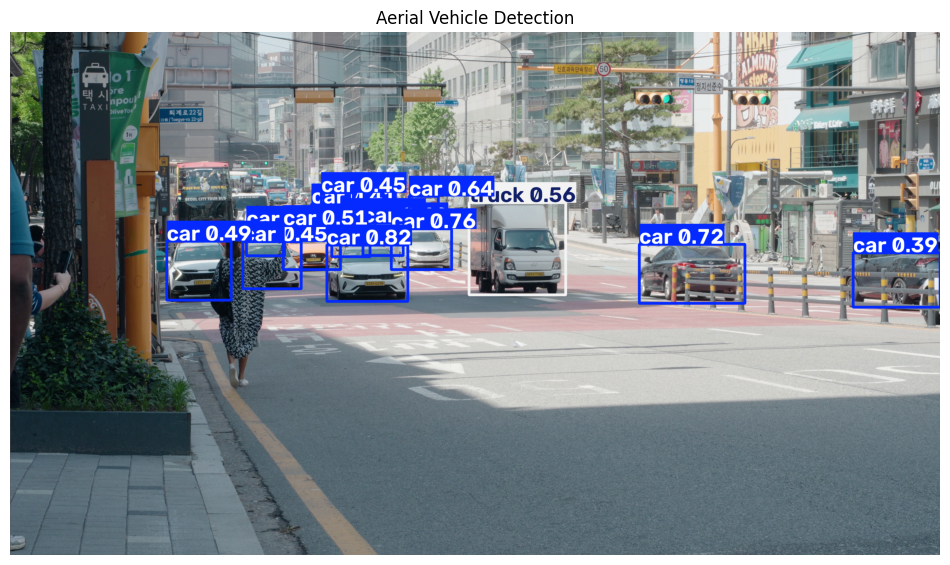

In [20]:
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO
from huggingface_hub import hf_hub_download, model_info

# Step 1: Verify repository
repo_id = "sobucki/droneflow-yolov8n-visdrone-vehicles"

try:
    info = model_info(repo_id)

    print("Repository found!")
    print("Available files:")

    for file in info.siblings:
        print(file.rfilename)

except Exception as e:
    raise RuntimeError(f"Repository access failed: {e}")

# Step 2: Download model weights
weights_path = hf_hub_download(
    repo_id="sobucki/droneflow-yolov8n-visdrone-vehicles",
    filename="weights/best.pt"
)

model = YOLO(weights_path)

print("Model loaded successfully!")
print("Available classes:", model.names)

# Step 4: Open video
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Could not open uploaded video.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("\nFPS:", fps)
print("Total frames:", total_frames)
print("Duration:", round(total_frames / fps, 2), "seconds")

# Step 5: Read sample frame
calibration_time = 2

cap.set(cv2.CAP_PROP_POS_MSEC, calibration_time * 1000)

success, frame = cap.read()

if not success:
    raise ValueError("Could not read calibration frame.")

# Step 6: Detect vehicles
results = model.predict(
    frame,
    conf=0.30,
    imgsz=640,
    verbose=False
)

detections = results[0].boxes

print("\nDetected objects:")

for i, box in enumerate(detections):
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    confidence = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    pixel_width = x2 - x1

    print(
        f"Index: {i} | "
        f"Object: {class_name} | "
        f"Confidence: {confidence:.2f} | "
        f"Width: {pixel_width:.1f} pixels"
    )

# Step 7: Display results
plt.figure(figsize=(12, 7))

plt.imshow(
    cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)
)

plt.axis("off")
plt.title("Aerial Vehicle Detection")
plt.show()

cap.release()

In [21]:

# Select the reference detection index from Cell 3
reference_index = int(input("Enter reference object index: "))

reference_box = detections[reference_index]

reference_class_id = int(reference_box.cls[0])
reference_class = model.names[reference_class_id]

x1, y1, x2, y2 = reference_box.xyxy[0].cpu().numpy()

reference_pixel_width = float(x2 - x1)

# Enter measured physical dimensions
real_width = float(
    input("Enter actual object width in meters: ")
)

known_distance = float(
    input("Enter actual camera-to-object distance in meters: ")
)

if real_width <= 0 or known_distance <= 0 or reference_pixel_width <= 0:
    raise ValueError("All calibration values must be positive.")

# Calculate focal length
focal_length = (
    reference_pixel_width * known_distance
) / real_width

print("\nCalibration successful!")
print("Reference class:", reference_class)
print("Reference width:", real_width, "meters")
print("Reference distance:", known_distance, "meters")
print("Focal length:", round(focal_length, 2), "pixels")


Enter reference object index: 14
Enter actual object width in meters: 12
Enter actual camera-to-object distance in meters: 12

Calibration successful!
Reference class: car
Reference width: 12.0 meters
Reference distance: 12.0 meters
Focal length: 157.7 pixels


In [22]:

import os

# Reopen video
cap = cv2.VideoCapture(video_path)

video_fps = cap.get(cv2.CAP_PROP_FPS)
video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if video_fps <= 0:
    video_fps = 25

output_path = "object_detection_distance.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    output_path,
    fourcc,
    video_fps,
    (video_width, video_height)
)

if not out.isOpened():
    raise RuntimeError("Could not create output video.")

records = []
frame_number = 0

print("Processing video...")

while True:
    success, frame = cap.read()

    if not success:
        break

    frame_number += 1

    # Detect objects
    results = model.predict(
        frame,
        conf=0.35,
        verbose=False
    )

    boxes = results[0].boxes

    for box in boxes:

        class_id = int(box.cls[0])
        class_name = model.names[class_id]

        confidence = float(box.conf[0])

        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

        x1, y1, x2, y2 = map(
            int, [x1, y1, x2, y2]
        )

        pixel_width = x2 - x1

        # Estimate distance only for calibrated class
        distance = None

        if (
            class_id == reference_class_id
            and pixel_width > 0
        ):
            distance = (
                real_width * focal_length
            ) / pixel_width

        # Prepare label
        if distance is not None:
            label = (
                f"{class_name}: "
                f"{distance:.2f} m "
                f"({confidence:.2f})"
            )
        else:
            label = (
                f"{class_name}: "
                f"Distance N/A "
                f"({confidence:.2f})"
            )

        # Draw bounding box
        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            frame,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

        # Save detection data
        records.append({
            "frame": frame_number,
            "timestamp_seconds": frame_number / video_fps,
            "object": class_name,
            "confidence": round(confidence, 4),
            "pixel_width": round(pixel_width, 2),
            "distance_meters": (
                round(distance, 2)
                if distance is not None
                else None
            ),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

    # Save annotated frame
    out.write(frame)

    if frame_number % 100 == 0:
        print("Processed frames:", frame_number)

cap.release()
out.release()

# Save detection results
df = pd.DataFrame(records)

csv_path = "detection_results.csv"
df.to_csv(csv_path, index=False)

print("\nProcessing completed!")
print("Total frames processed:", frame_number)
print("Total detections:", len(df))
print("Video saved:", output_path)
print("CSV saved:", csv_path)


Processing video...
Processed frames: 100
Processed frames: 200
Processed frames: 300
Processed frames: 400
Processed frames: 500
Processed frames: 600

Processing completed!
Total frames processed: 601
Total detections: 7146
Video saved: object_detection_distance.mp4
CSV saved: detection_results.csv


Detection summary:
   frame  timestamp_seconds object  confidence  pixel_width  distance_meters  \
0      1           0.041708    car      0.8148          149            12.70   
1      1           0.041708    car      0.8103          228             8.30   
2      1           0.041708    car      0.8102          296             6.39   
3      1           0.041708    car      0.6986          221             8.56   
4      1           0.041708    car      0.6582          313             6.05   
5      1           0.041708    car      0.6439          172            11.00   
6      1           0.041708    car      0.6177          174            10.88   
7      1           0.041708    car      0.6067          134            14.12   
8      1           0.041708    car      0.5661          239             7.92   
9      1           0.041708    car      0.4355          165            11.47   

     x1   y1    x2    y2  
0  1651  706  1800   800  
1  1590  855  1818  1023  
2  1289  913  1585 

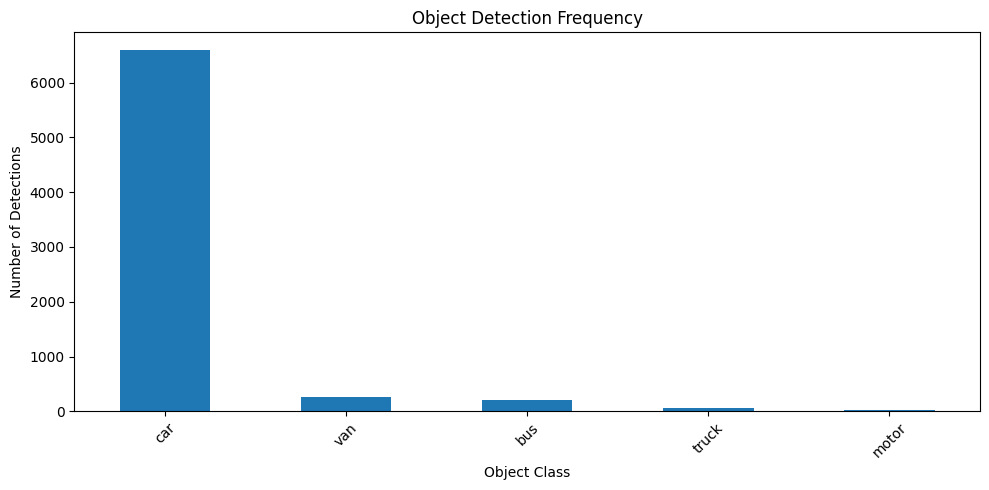

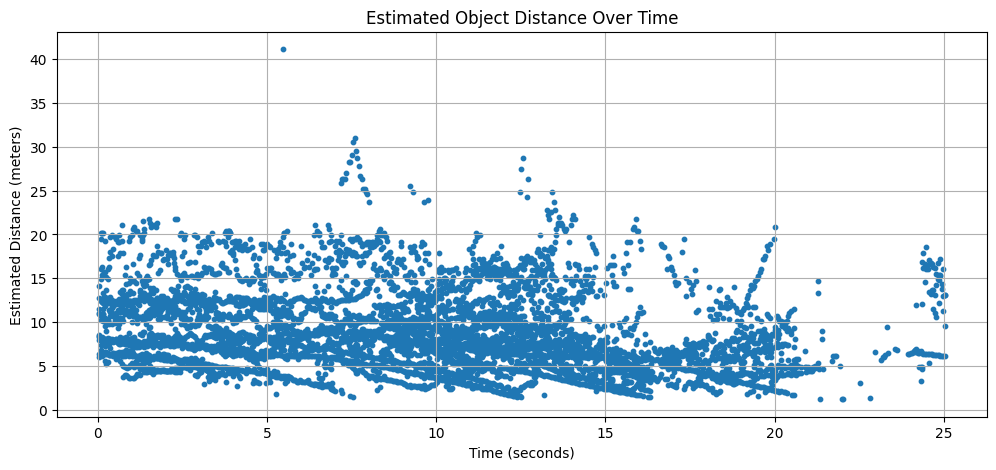

In [23]:

print("Detection summary:")
print(df.head(10))

print("\nObjects detected:")
print(df["object"].value_counts())

# Distance statistics for calibrated object class
distance_df = df.dropna(subset=["distance_meters"])

print("\nDistance statistics:")
if not distance_df.empty:
    print(
        distance_df.groupby("object")[
            "distance_meters"
        ].describe()
    )
else:
    print("No calibrated objects were detected.")

# Plot object detection counts
plt.figure(figsize=(10, 5))

df["object"].value_counts().plot(
    kind="bar"
)

plt.title("Object Detection Frequency")
plt.xlabel("Object Class")
plt.ylabel("Number of Detections")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot estimated distance over time
if not distance_df.empty:

    plt.figure(figsize=(12, 5))

    plt.scatter(
        distance_df["timestamp_seconds"],
        distance_df["distance_meters"],
        s=10
    )

    plt.title("Estimated Object Distance Over Time")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Estimated Distance (meters)")
    plt.grid(True)
    plt.show()


In [ ]:

from IPython.display import Video, display
from google.colab import files

print("Final annotated video:")

display(
    Video(
        output_path,
        embed=True,
        width=800
    )
)

# Download annotated video
files.download(output_path)

# Download CSV
files.download(csv_path)
